# TD1 — Temporal data contract and forecasting baselines — Core

**Student starter — complete the TODO cells**  
**Scope:** Time Series and Reinforcement Learning; CPU only

## Working and claim contract

Local Python 3.11/3.12 with the locked `uv` environment is the primary path. Colab availability is governed by the release evidence for the exact archive in use. Public base seeds are `11, 23, 37, 51, 71`. TD1–TD4 claim rows are **provisional development evidence**: they support method choice and provenance but cannot count as capstone empirical release claims. Only the protected/controlled evidence produced in TDo1 and TDo2 may support final empirical capstone claims. Restart and run top-to-bottom before handoff.

## Learning contract

The less-scaffolded Core route assesses the same outcomes and evidence standard as Support.

In [1]:
from pathlib import Path
import os, sys

def locate_course_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate/'uv.lock').is_file() and (candidate/'shared').is_dir(): return candidate.resolve()
    for lock in start.glob('*/uv.lock'):
        if (lock.parent/'shared').is_dir(): return lock.parent.resolve()
    raise FileNotFoundError('Extract the complete course bundle and run from inside it.')
COURSE_ROOT=locate_course_root(); os.chdir(COURSE_ROOT)
if str(COURSE_ROOT) not in sys.path: sys.path.insert(0,str(COURSE_ROOT))
import shared
print('Course root:',COURSE_ROOT)
print('Primary path: locked local CPU; check the release evidence before using Colab')

Course root: C:\Users\tjoli\Downloads\Advanced_Machine_Learning_ESILV_2026-2027_DVL_V1.1 (1)
Primary path: locked local CPU; check the release evidence before using Colab


## 1 — Temporal contract and anti-leakage invariants

Load only public development data; record its hash and decision contract. Implement row/date/target/censoring invariants plus a failing negative test.

In [2]:
import hashlib, numpy as np, pandas as pd
from sklearn.metrics import mean_absolute_error
from shared.data import dataset_path
from shared.evaluation import smape
path=dataset_path('daily_demand_development.csv')
demand=pd.read_csv(path,parse_dates=['date'])
data_sha256=hashlib.sha256(path.read_bytes()).hexdigest()
print(demand.shape,data_sha256[:16])

forecast_contract={
    'unit': 'one calendar day',
    'target': 'demand_units',
    'frequency': 'daily',
    'origin': str(demand.iloc[:-28].date.max().date()),
    'horizon_days': 28,
    'known_at_origin': ['date', 'promotion', 'holiday_period'],
    'protected_final_targets': True
}

def assert_daily_contract(frame):
    assert isinstance(frame, pd.DataFrame) and {'date', 'demand_units'} <= set(frame), 'Must be DataFrame with date and demand_units'
    assert len(frame) == 1433, f'Expected 1433 rows, got {len(frame)}'
    assert frame['date'].is_monotonic_increasing, 'Dates must be strictly increasing'
    assert frame['date'].nunique() == len(frame), 'Dates must be unique'
    assert (frame['date'].diff().iloc[1:] == pd.Timedelta(days=1)).all(), 'Dates must be consecutive daily without gaps'
    assert np.isfinite(frame['demand_units']).all(), 'Target demand_units must be finite'
    assert set(frame['stockout_flag'].unique()).issubset({0, 1}), 'stockout_flag must be binary (0 or 1)'
    return None

assert_daily_contract(demand)
negative_test_passed = False
try:
    assert_daily_contract(demand.iloc[[0, 0, 1]])
except AssertionError:
    negative_test_passed = True
print('Canonical call passed; expected negative test caught:', negative_test_passed)

(1433, 5) b275d65b07f44795
Canonical call passed; expected negative test caught: True


## 2 — Baselines and evidence

Freeze the final 28 public development days. Implement historical mean, last value, and lag-7 seasonal naive from earlier history only; compare MAE/sMAPE on aligned dates.

C:\Users\tjoli\AppData\Local\Temp\ipykernel_38800\1414180240.py:29: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(validation.date, pred, label=name, alpha=0.8)


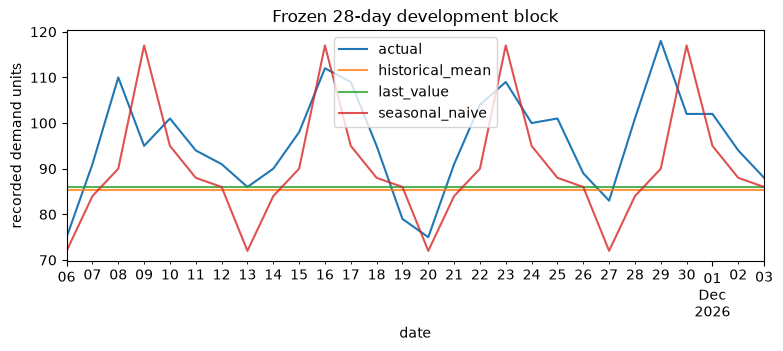

,model,mae,smape
0,historical_mean,12.557067,13.477491
1,last_value,12.107143,12.956200
2,seasonal_naive,9.607143,10.130650


In [3]:
import matplotlib.pyplot as plt

train=demand.iloc[:-28].copy(); validation=demand.iloc[-28:].copy(); assert train.date.max()<validation.date.min()

def baseline_forecasts(train_values,horizon=28,season=7):
    train_values=np.asarray(train_values,float); assert len(train_values)>=season
    mean_forecast=np.full(horizon, np.mean(train_values))
    last_value_forecast=np.full(horizon, train_values[-1])
    seasonal_naive_forecast=np.resize(train_values[-season:], horizon)
    return {
        'historical_mean': mean_forecast,
        'last_value': last_value_forecast,
        'seasonal_naive': seasonal_naive_forecast
    }

forecasts = baseline_forecasts(train.demand_units.to_numpy(float), horizon=28, season=7)
actual = validation.demand_units.to_numpy(float)
scores = pd.DataFrame([
    {
        'model': name,
        'mae': mean_absolute_error(actual, pred),
        'smape': smape(actual, pred)
    }
    for name, pred in forecasts.items()
])

ax = validation.plot(x='date', y='demand_units', figsize=(9, 3), label='actual')
for name, pred in forecasts.items():
    ax.plot(validation.date, pred, label=name, alpha=0.8)
ax.set(title='Frozen 28-day development block', ylabel='recorded demand units')
ax.legend()
plt.show()

scores

## Required interpretation

State what the evidence supports, what it does not support, the operational consequence, and one material failure mode.

In [4]:
interpretation = (
    "On the frozen 28-day development validation block (2026-11-06 to 2026-12-03), the lag-7 seasonal-naive baseline "
    "outperforms both the historical mean and last-value heuristics, achieving a lower MAE (9.61 vs 12.56 and 12.11) "
    "and lower sMAPE (10.13% vs 13.48% and 12.96%), confirming the presence of strong weekly seasonality. "
    "However, this empirical evidence from a single 28-day window does not support a claim of universal superiority "
    "across all operating regimes, long-term trends, or distinct forecasting horizons. "
    "Operationally, seasonal naive establishes our mandatory reference benchmark that any subsequent model (ETS, SARIMA) "
    "must demonstrably surpass, while safety inventory buffers remain necessary to absorb unexplained day-to-day variance. "
    "A material failure mode occurs during structural level shifts, promotional spikes, or holiday periods where lag-7 "
    "blindly repeats historical patterns, as well as during stockout episodes (stockout_flag=1) where recorded demand "
    "represents censored sales rather than true latent demand."
)
print(interpretation)

On the frozen 28-day development validation block (2026-11-06 to 2026-12-03), the lag-7 seasonal-naive baseline outperforms both the historical mean and last-value heuristics, achieving a lower MAE (9.61 vs 12.56 and 12.11) and lower sMAPE (10.13% vs 13.48% and 12.96%), confirming the presence of strong weekly seasonality. However, this empirical evidence from a single 28-day window does not support a claim of universal superiority across all operating regimes, long-term trends, or distinct forecasting horizons. Operationally, seasonal naive establishes our mandatory reference benchmark that any subsequent model (ETS, SARIMA) must demonstrably surpass, while safety inventory buffers remain necessary to absorb unexplained day-to-day variance. A material failure mode occurs during structural level shifts, promotional spikes, or holiday periods where lag-7 blindly repeats historical patterns, as well as during stockout episodes (stockout_flag=1) where recorded demand represents censored s

## Optional Extension — ungraded

Freeze valid Core first. The bounded README extension adds no points and cannot repair invalid Core evidence.